# 2. Filter settings and BW + PLI (Sec. IV-A, Figs. 6, 7, 8)

Tuned filter settings (`scripts/02_tune_filters.py`) and the BW + PLI results
(`scripts/03_bw_pli.py`). Plots: "X ours" solid / filled, "X paper" dashed / hatched.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from src.config import FIGURES_DIR, RESULTS_DIR
pd.set_option("display.precision", 2)

In [2]:
import json
params = json.loads((RESULTS_DIR / "tuned_filter_params.json").read_text())
pd.DataFrame({m: {f: ", ".join(f"{k}={v:g}" for k, v in s.items()) for f, s in p.items()}
              for m, p in params.items()}).T.fillna("")

,pli,bw,em,ma,all
EMD+LMS,"mu=0.01, taps=16","mu=0.0003, taps=8",,,
EMD+NLMS,"mu=0.03, taps=16","mu=0.001, taps=64",,,
EMD+RLS,"lam=1, taps=4","lam=1, taps=8",,,
PEAF,"mu=0.03, taps=4","mu=3e-05, taps=32","mu=0.0001, taps=8","mu=0.003, taps=4",
SEAF,"mu=0.03, taps=4","mu=0.0001, taps=8","mu=0.0001, taps=8","mu=0.003, taps=4",
PDAF,,,,,"mu=0.0003, taps=8"
SDAF,"mu=0.003, taps=16","mu=0.0001, taps=8","mu=0.0001, taps=8","mu=0.003, taps=4",


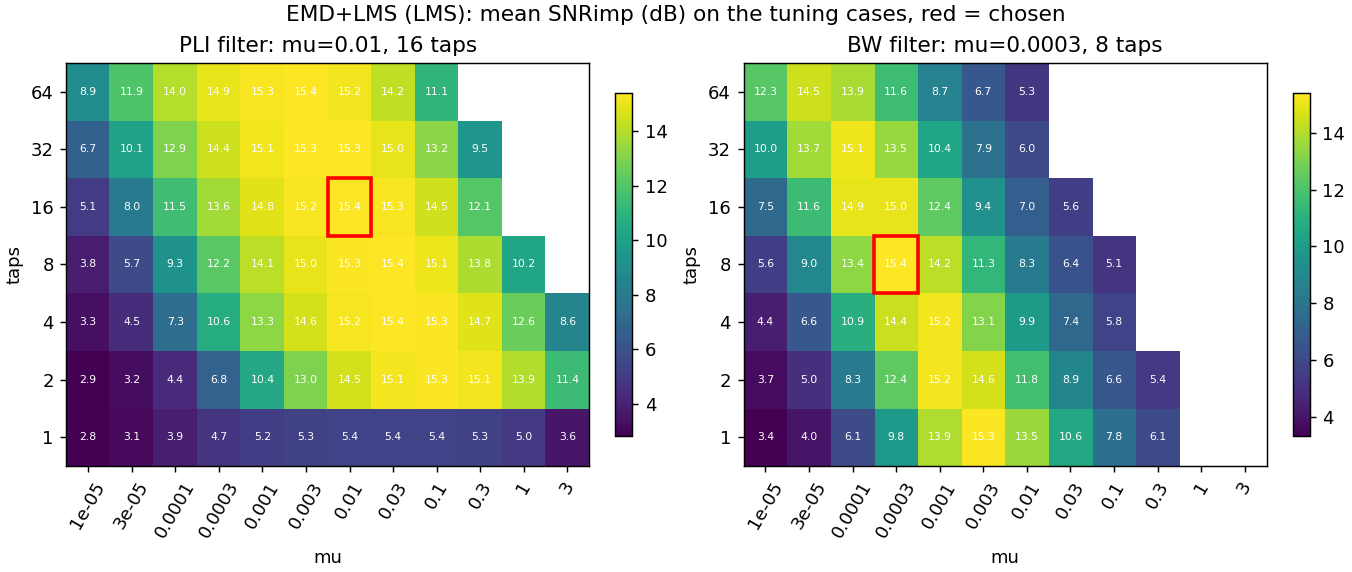

In [3]:
display(Image(FIGURES_DIR / "filter_tuning_mean_snr_imp_emd_lms.png", width=900))

## Fig. 6: example

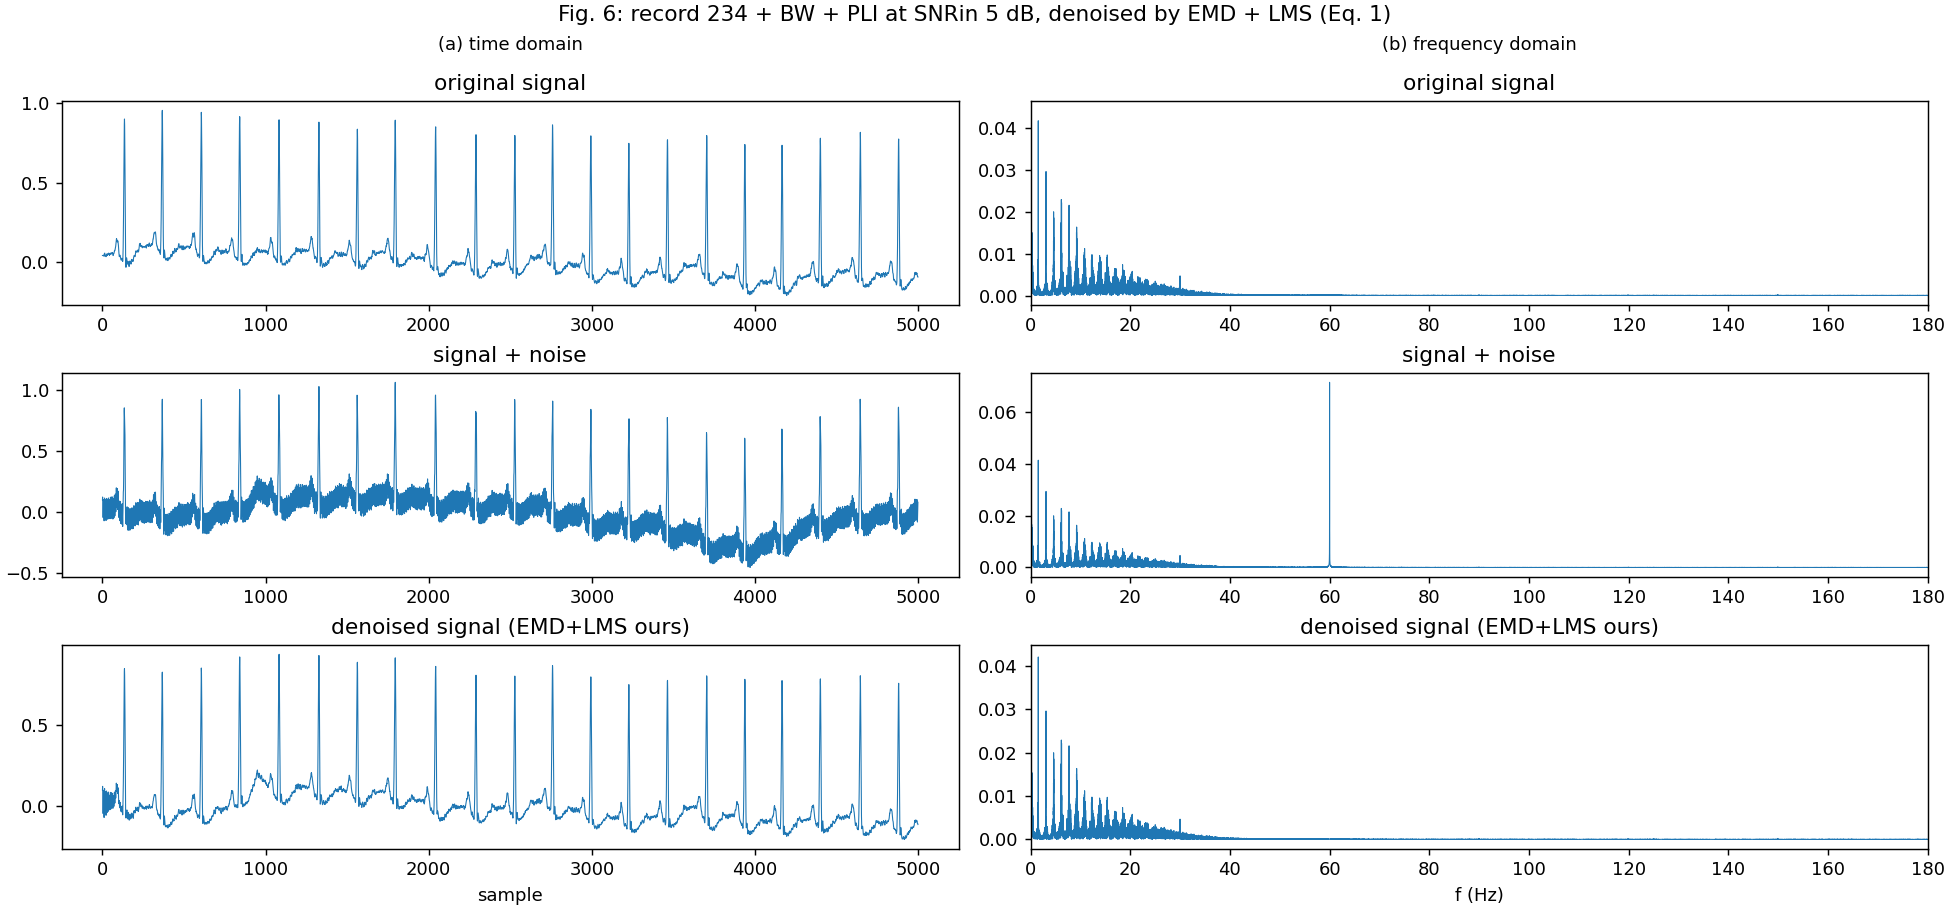

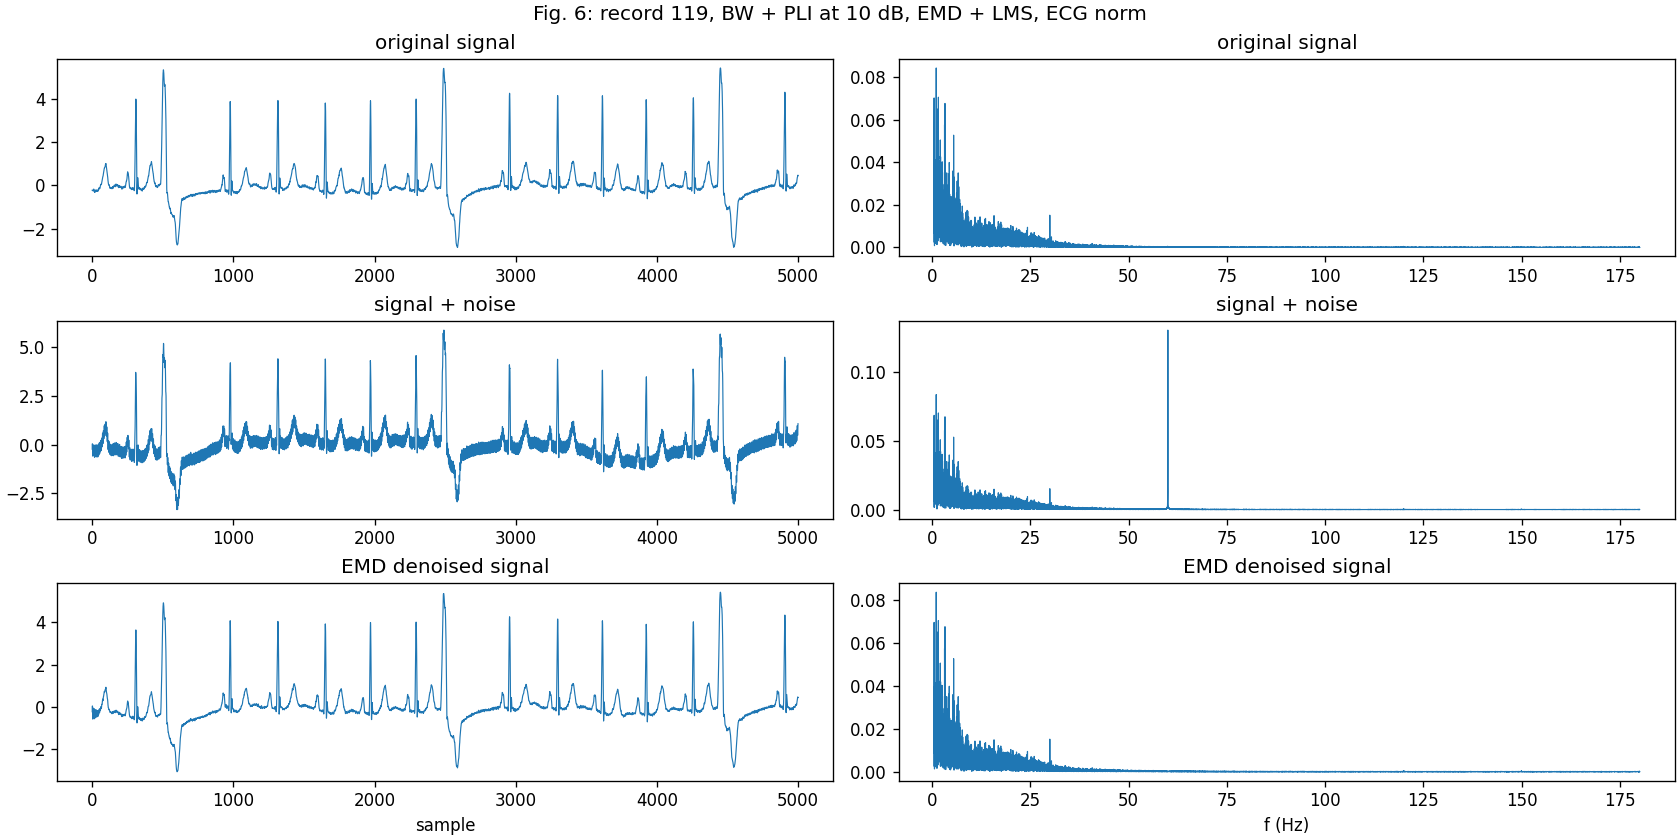

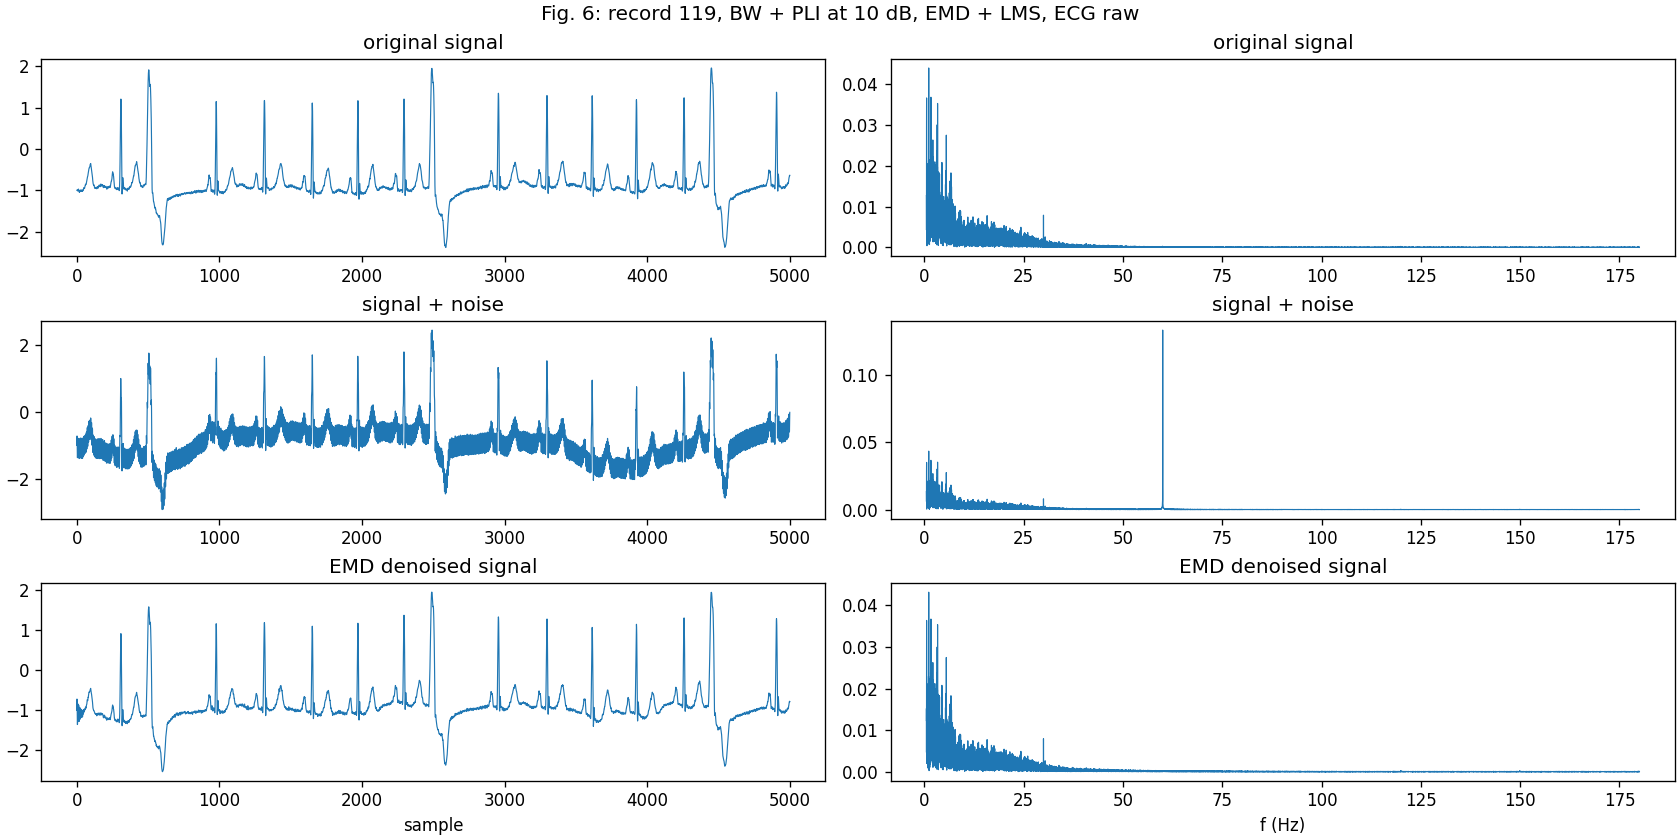

In [4]:
display(*[Image(p, width=1000) for p in sorted(FIGURES_DIR.glob("fig6_*.png"))])

## Fig. 7: LMS vs RLS vs NLMS (mean over the Fig. 8 records)

In [5]:
from src import paper_values as paper
from src.config import FIG7_RECORDS
bw = pd.read_csv(RESULTS_DIR / "bw_pli.csv")
d = bw[bw.record.isin(FIG7_RECORDS)]
for column, values in [("SNRout_dB", paper.FIG7_SNR_OUT), ("RMSE", paper.FIG7_RMSE)]:
    ours = d.groupby(["method", "SNRin_dB"])[column].mean().unstack()
    theirs = pd.DataFrame(values, index=paper.FIG7_SNRS).T
    display(Markdown(f"**{column}**"), pd.concat({"ours": ours, "paper": theirs.loc[ours.index]}, axis=1))

**SNRout_dB**

ours                             paper                        
SNRin_dB    -5      0      5      7      10   -5     0     5     7     10
method                                                                   
EMD+LMS   13.43  17.33  20.11  20.62  21.42  10.0  11.0  12.4  17.3  22.2
EMD+NLMS   9.75  11.72  12.72  12.42  13.32   5.1   7.2  13.1  18.6  24.4
EMD+RLS   20.18  21.04  23.81  23.55  23.62   8.2   9.1  12.2  16.6  21.9

**RMSE**

ours                         paper                            
SNRin_dB   -5     0     5     7     10   -5     0     5     7         10
method                                                                  
EMD+LMS   0.04  0.02  0.02  0.02  0.02  0.05  0.05  0.04  0.02  1.20e-02
EMD+NLMS  0.06  0.05  0.04  0.04  0.04  0.09  0.07  0.04  0.02  9.00e-03
EMD+RLS   0.02  0.02  0.01  0.01  0.01  0.06  0.06  0.04  0.02  1.30e-02

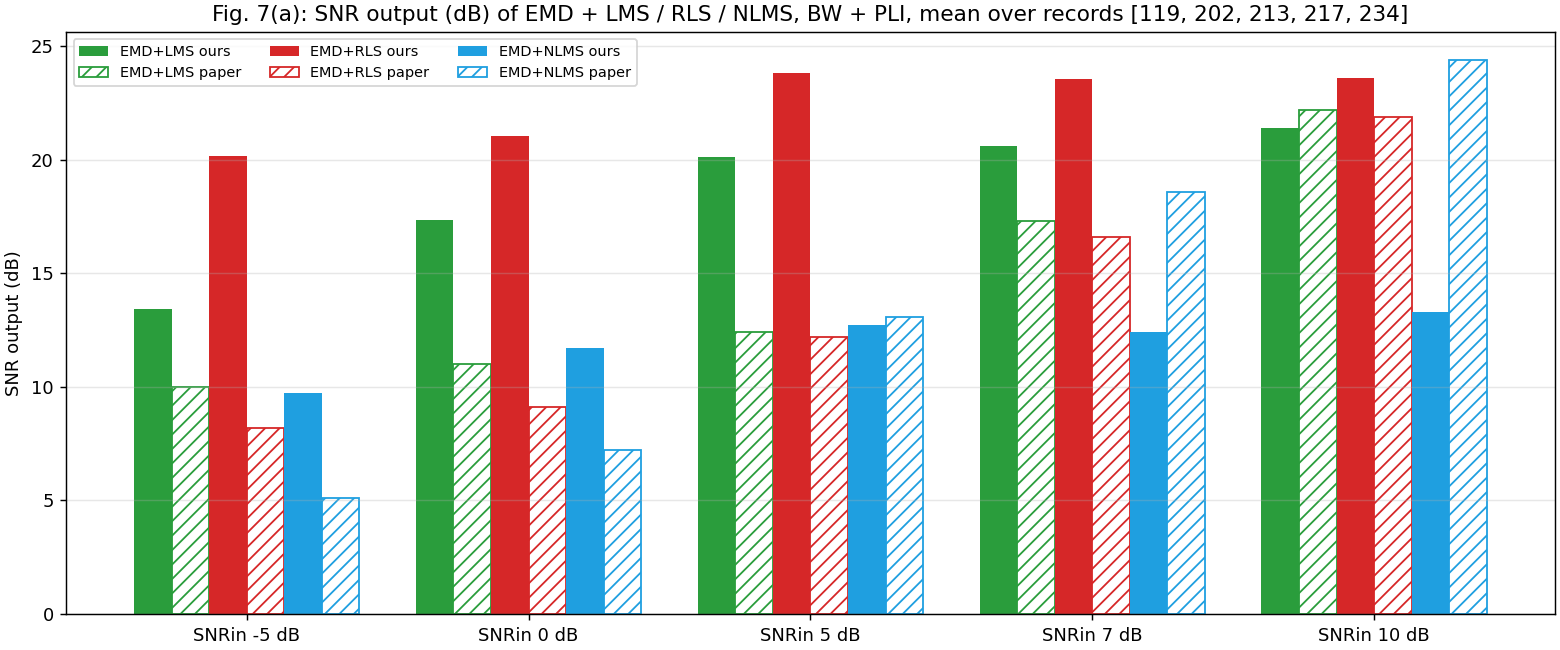

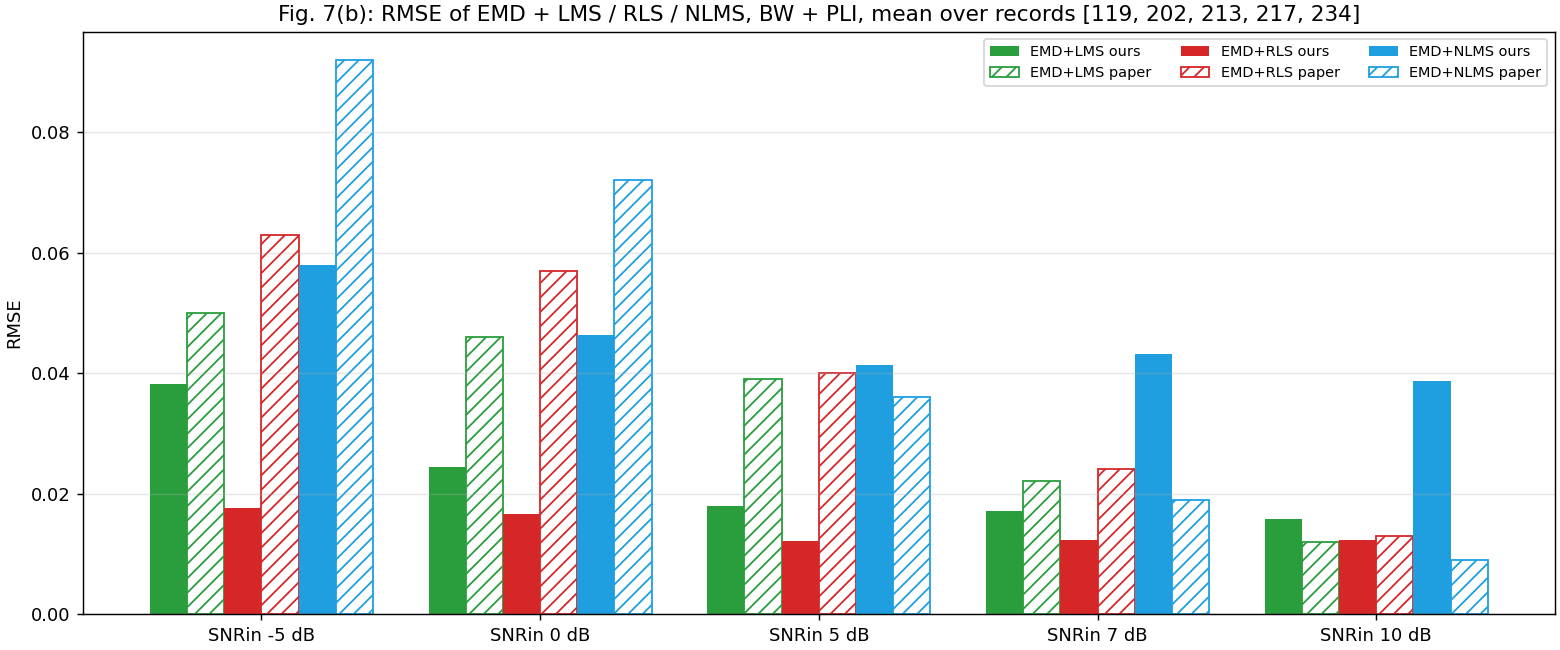

In [6]:
display(Image(FIGURES_DIR / "fig7a_snr_out_lms_rls_nlms_vs_snr_in_bw_pli.png", width=1000),
        Image(FIGURES_DIR / "fig7b_rmse_lms_rls_nlms_vs_snr_in_bw_pli.png", width=1000))

## Fig. 8: SNR output per record at SNRin = 10 dB

In [7]:
ours = bw[(bw.SNRin_dB == 10) & (bw.method == "EMD+LMS")].set_index("record").SNRout_dB
table = pd.DataFrame(paper.FIG8_SNR_OUT, index=paper.FIG8_RECORDS).add_suffix(" paper")
table.insert(0, "EMD+LMS ours", ours.loc[paper.FIG8_RECORDS])
table

,EMD+LMS ours,EMD+LMS paper,Article [28] paper,Article [21] paper,Article [22] paper
119,24.85,24.7,18.0,16.5,14.0
202,19.45,22.9,23.0,20.5,18.9
213,23.70,25.0,20.0,18.0,16.0
217,20.26,29.2,26.0,24.0,23.1
234,18.86,23.9,20.5,19.0,18.6


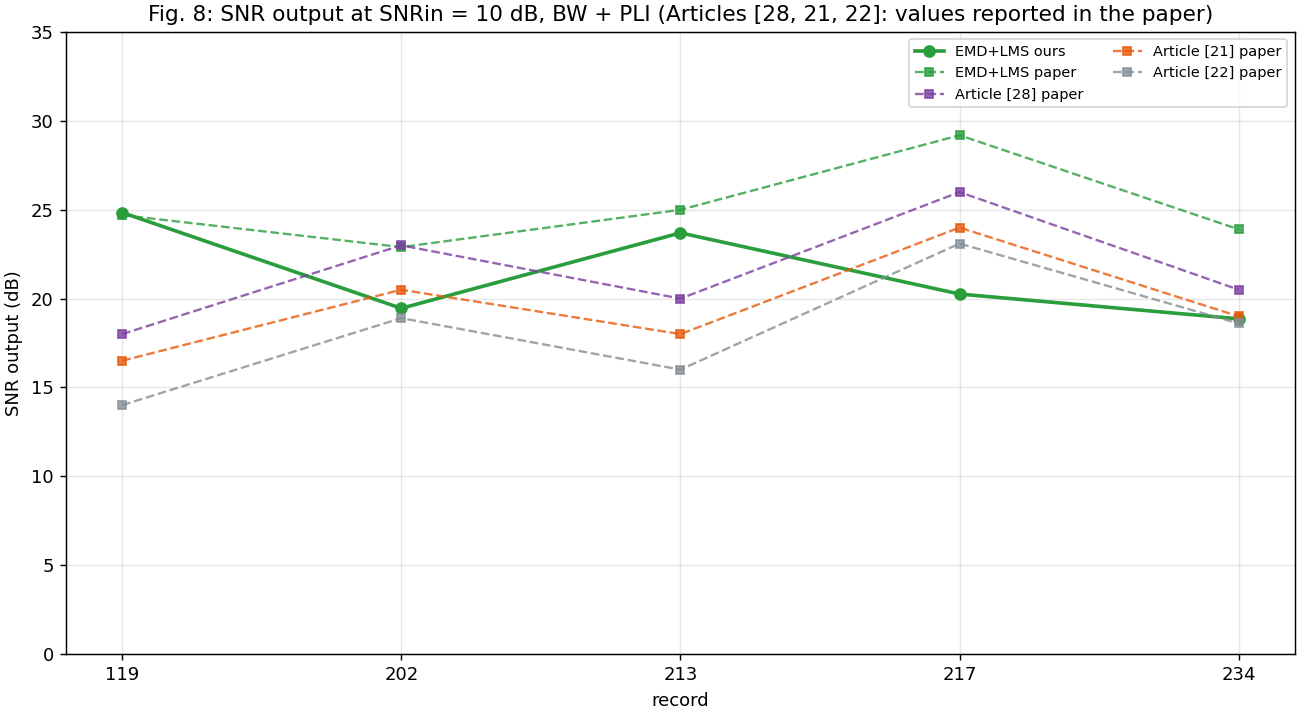

In [8]:
display(Image(FIGURES_DIR / "fig8_snr_out_per_record_emd_lms_vs_articles_snr_in_10dB.png", width=900))